# **Time series Modeling and Forcast for AMZN dataset and jj dataset**

# **Import libraries and Functions**

In [ ]:
# ===============================
# Common Imports and Functions
# ===============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM
from tensorflow.keras.callbacks import EarlyStopping


# **Function to Perform ADF Test for Both datasets**

In [ ]:
# Function to perform ADF test and print results
def adf_test(timeseries, title='ADF Test'):
    print(f"--- {title} ---")
    result = adfuller(timeseries.dropna())
    print("ADF Statistic: {:.4f}".format(result[0]))
    print("p-value: {:.4f}".format(result[1]))
    if result[1] > 0.05:
        print("=> The series is likely non-stationary. Consider differencing.\n")
    else:
        print("=> The series appears stationary.\n")

# **Function to create sequences for LSTM input for Both datasets**

In [ ]:
# Function to create sequences for LSTM input
def create_dataset(dataset, time_step=60):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        X.append(dataset[i:i + time_step, 0])
        y.append(dataset[i + time_step, 0])
    return np.array(X), np.array(y)


# **Part 1: AMZN Dataset Analysis &Training**

In [ ]:

# 1. Load and Preprocess AMZN Dataset
data_amzn = pd.read_csv('AMZN.csv')  # Load AMZN dataset
data_amzn['Date'] = pd.to_datetime(data_amzn['Date'])
data_amzn.set_index('Date', inplace=True)
data_amzn = data_amzn.asfreq('B')  # Adjust frequency to business days (e.g., weekdays)


In [ ]:
# Check for missing values in AMZN dataset
print("\nMissing values in AMZN dataset:")
print(data_amzn.isna().sum())


Missing values in AMZN dataset:
Open         45
High         45
Low          45
Close        45
Adj Close    45
Volume       45
dtype: int64


In [ ]:
# Handle missing values (if any) by forward filling
data_amzn.fillna(method='ffill', inplace=True)

# We will use the 'Close' price as the target variable.
ts_amzn = data_amzn['Close']

In [ ]:
print(data_amzn.isna().sum())

Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


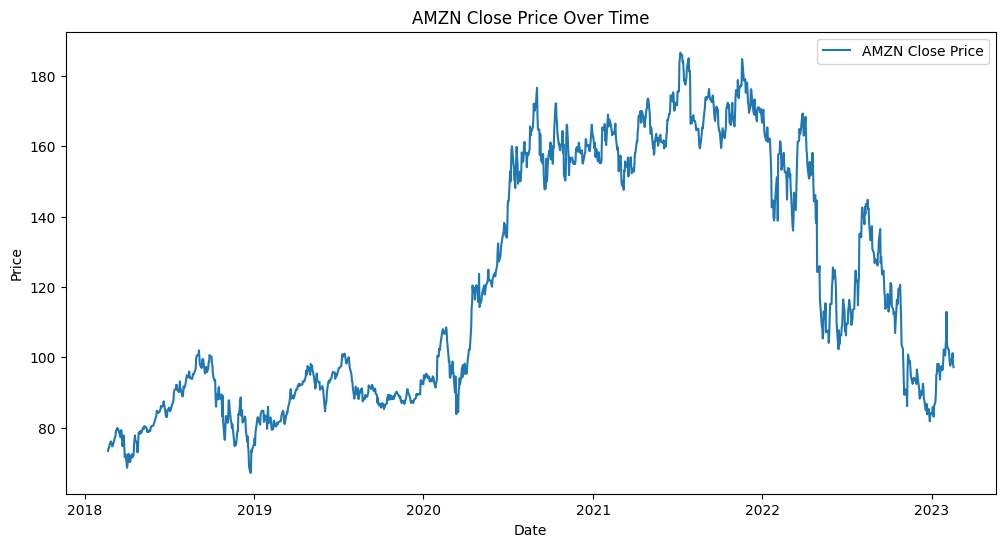

In [ ]:
# 2. Plot the AMZN Time Series
plt.figure(figsize=(12, 6))
plt.plot(ts_amzn, label='AMZN Close Price')
plt.title("AMZN Close Price Over Time")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

# **ARIMA Modeling for AMZN Dataset**

In [ ]:
# Function to perform ADF test and print results
def adf_test(timeseries, title='ADF Test'):
    print(f"--- {title} ---")
    result = adfuller(timeseries.dropna())
    print("ADF Statistic: {:.4f}".format(result[0]))
    print("p-value: {:.4f}".format(result[1]))
    if result[1] > 0.05:
        print("=> The series is likely non-stationary. Consider differencing.\n")
    else:
        print("=> The series appears stationary.\n")

# 3. Stationarity Test for AMZN Data
adf_test(ts_amzn, title="AMZN Close Price - ADF Test")



--- AMZN Close Price - ADF Test ---
ADF Statistic: -1.6556
p-value: 0.4541
=> The series is likely non-stationary. Consider differencing.



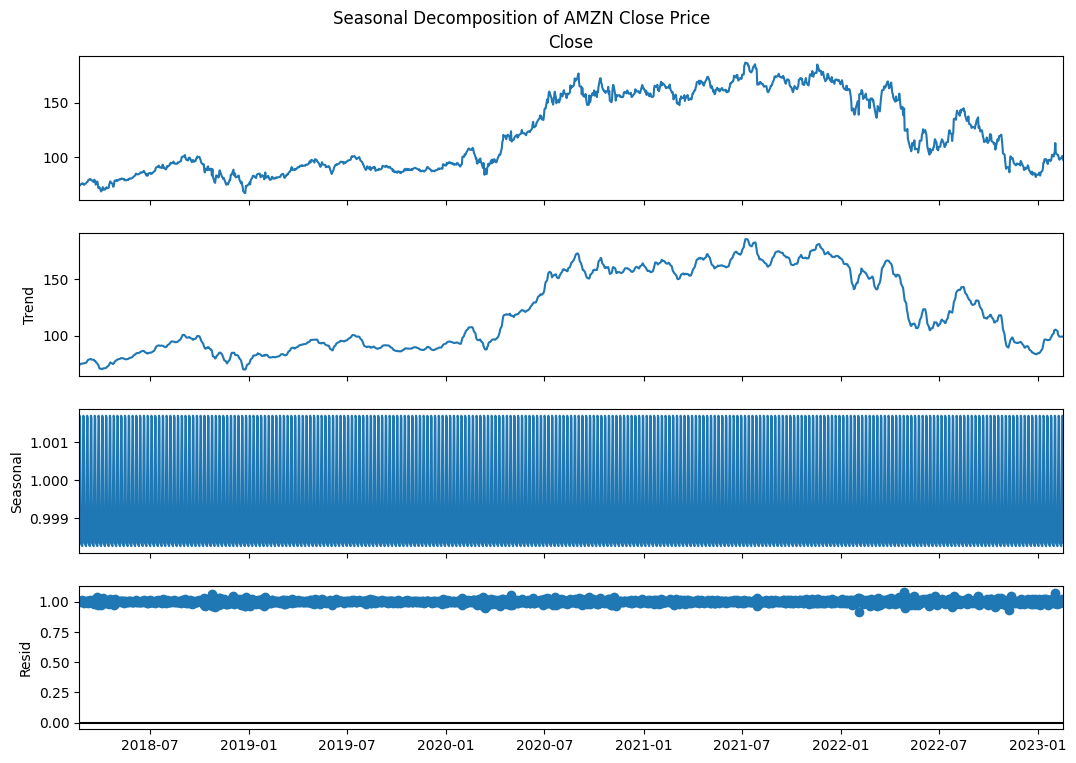

In [ ]:
# 4. Seasonal Decomposition for AMZN Data
try:
    decomposition_amzn = seasonal_decompose(ts_amzn, model='multiplicative')
    fig = decomposition_amzn.plot()
    fig.set_size_inches(12, 8)
    plt.suptitle("Seasonal Decomposition of AMZN Close Price")
    plt.show()
except Exception as e:
    print("Seasonal Decomposition Error:", e)

In [ ]:

# 5. Differencing the Series (if the series is non-stationary)
diff_ts_amzn = ts_amzn.diff().dropna()


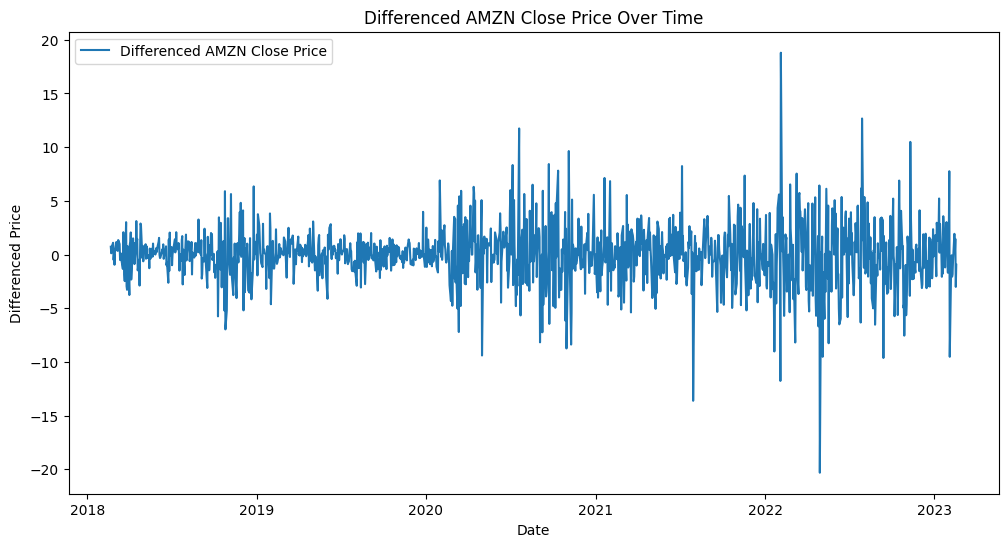

In [ ]:
# Plot the differenced series
plt.figure(figsize=(12, 6))
plt.plot(diff_ts_amzn, label='Differenced AMZN Close Price')
plt.title("Differenced AMZN Close Price Over Time")
plt.xlabel("Date")
plt.ylabel("Differenced Price")
plt.legend()
plt.show()

In [ ]:

# Run ADF test on differenced series to check stationarity
adf_test(diff_ts_amzn, title="Differenced AMZN Close Price - ADF Test")

--- Differenced AMZN Close Price - ADF Test ---
ADF Statistic: -37.2102
p-value: 0.0000
=> The series appears stationary.



In [ ]:
# 6. Split Data for ARIMA Modeling (80% train, 20% test)
train_size_amzn = int(len(diff_ts_amzn) * 0.8)
train_amzn = diff_ts_amzn.iloc[:train_size_amzn]
test_amzn = diff_ts_amzn.iloc[train_size_amzn:]
print("AMZN ARIMA Train samples:", len(train_amzn))
print("AMZN ARIMA Test samples:", len(test_amzn))

AMZN ARIMA Train samples: 1042
AMZN ARIMA Test samples: 261


In [ ]:
# 7. ARIMA Model on AMZN Data
# Use order (1, 0, 1) because the series is already differenced.
arima_model_amzn = ARIMA(train_amzn, order=(1, 0, 1))  #use ARIMA(1,1,1)=(p,d,q) when manual differencing is not applied
                                                       #to the data but in this case differencing is already
                                                        # applied so value of d = 0
arima_model_fit_amzn = arima_model_amzn.fit()
print(arima_model_fit_amzn.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1042
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -2402.903
Date:                Fri, 11 Apr 2025   AIC                           4813.806
Time:                        03:43:07   BIC                           4833.601
Sample:                    02-21-2018   HQIC                          4821.314
                         - 02-17-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0781      0.065      1.195      0.232      -0.050       0.206
ar.L1          0.6191      0.198      3.130      0.002       0.231       1.007
ma.L1         -0.6735      0.188     -3.580      0.0

In [ ]:
# 8. ARIMA Forecast for AMZN Data
forecast_steps_amzn = len(test_amzn)
forecast_amzn = arima_model_fit_amzn.forecast(steps=forecast_steps_amzn)
forecast_amzn.index = test_amzn.index

In [ ]:
# Invert (re-integrate) the ARIMA forecast to bring it back to original scale.
# Get the last original value from the training part of ts_amzn.
last_value_amzn = ts_amzn.iloc[train_size_amzn]
# Since diff_ts_amzn was ts_amzn.diff().dropna(), the test period in the original series starts at train_size_amzn+1.
forecast_amzn_inv = forecast_amzn.cumsum() + last_value_amzn
# Actual test values from original ts_amzn (aligned properly)
test_actual_amzn = ts_amzn.iloc[train_size_amzn+1:train_size_amzn+1+len(forecast_amzn_inv)]



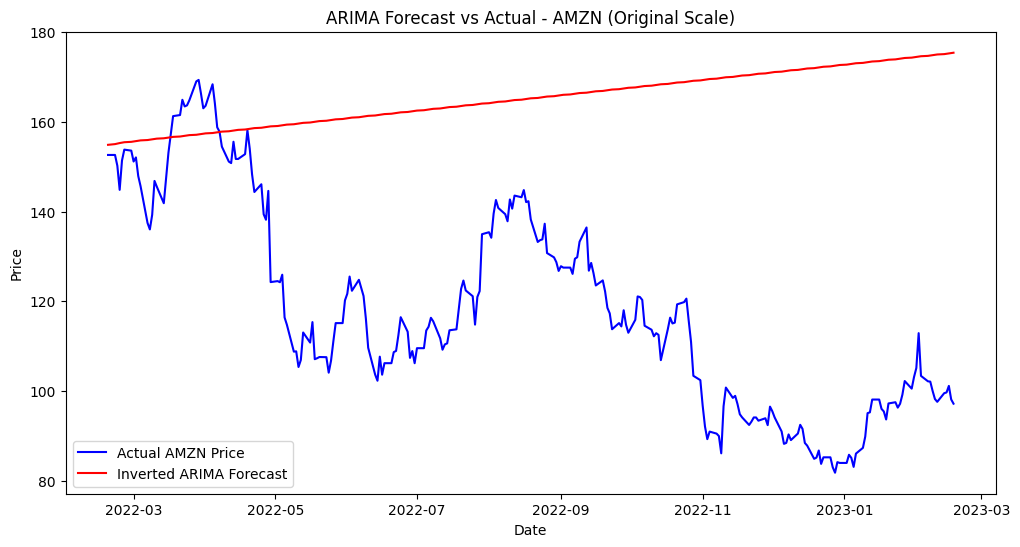

In [ ]:
# Plot ARIMA Forecast vs. Actual for AMZN (Original Scale)
plt.figure(figsize=(12, 6))
plt.plot(test_actual_amzn, label='Actual AMZN Price', color='blue')
plt.plot(forecast_amzn_inv, label='Inverted ARIMA Forecast', color='red')
plt.title("ARIMA Forecast vs Actual - AMZN (Original Scale)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

In [ ]:
# 9. Evaluate ARIMA Forecast for AMZN (Compare Inverted Forecast with Actual)
rmse_arima_amzn = np.sqrt(mean_squared_error(test_actual_amzn, forecast_amzn_inv))
mae_arima_amzn = mean_absolute_error(test_actual_amzn, forecast_amzn_inv)
print(f"AMZN ARIMA RMSE (inverted forecast): {rmse_arima_amzn:.2f}")
print(f"AMZN ARIMA MAE (inverted forecast): {mae_arima_amzn:.2f}")

AMZN ARIMA RMSE (inverted forecast): 54.41
AMZN ARIMA MAE (inverted forecast): 47.80


# **24-Month Future Forecast for AMZN using ARIMA**

In [ ]:
# Assuming approximately 21 business days per month, 24 months ~ 504 steps.
forecast_future_steps_amzn = 24 * 21  # Adjust if necessary
forecast_future_amzn = arima_model_fit_amzn.forecast(steps=forecast_future_steps_amzn)
# Create new index for future dates starting from the last date of the original series
future_dates_amzn = pd.date_range(start=ts_amzn.index[-1] + pd.Timedelta(days=1), periods=forecast_future_steps_amzn, freq='B')
forecast_future_amzn.index = future_dates_amzn
# Invert future forecast: use the last value from the original series
last_value_amzn_full = ts_amzn.iloc[-1]
forecast_future_amzn_inv = forecast_future_amzn.cumsum() + last_value_amzn_full


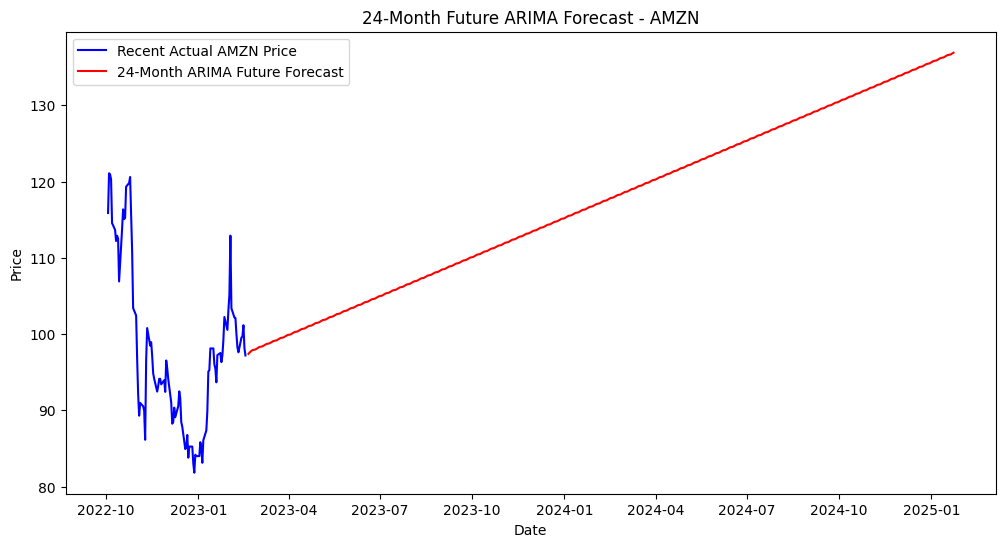

In [ ]:
# visual of 24 months forecast for AMZN
plt.figure(figsize=(12, 6))
plt.plot(ts_amzn.tail(100), label='Recent Actual AMZN Price', color='blue')  # recent data for context
plt.plot(forecast_future_amzn_inv, label='24-Month ARIMA Future Forecast', color='red')
plt.title("24-Month Future ARIMA Forecast - AMZN")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

# **LSTM Modeling for AMZN Dataset**

In [ ]:
# Scale the data
values_amzn = ts_amzn.values.reshape(-1, 1)
scaler_amzn = MinMaxScaler(feature_range=(0, 1))
scaled_amzn = scaler_amzn.fit_transform(values_amzn)


In [ ]:
# Create sequences for LSTM
time_step = 60  # window length (adjust if needed)
X_amzn, y_amzn = create_dataset(scaled_amzn, time_step)

In [ ]:
# Split into training and test sets for LSTM
train_size_lstm_amzn = int(len(X_amzn) * 0.8)   # 80 % training and 20 % for testing
X_train_amzn, X_test_amzn = X_amzn[:train_size_lstm_amzn], X_amzn[train_size_lstm_amzn:]
y_train_amzn, y_test_amzn = y_amzn[:train_size_lstm_amzn], y_amzn[train_size_lstm_amzn:]
print("AMZN LSTM Train samples:", X_train_amzn.shape[0])
print("AMZN LSTM Test samples:", X_test_amzn.shape[0])

AMZN LSTM Train samples: 995
AMZN LSTM Test samples: 249


In [ ]:
# Reshape for LSTM input: [samples, time steps, features]
X_train_amzn = X_train_amzn.reshape((X_train_amzn.shape[0], X_train_amzn.shape[1], 1))
X_test_amzn = X_test_amzn.reshape((X_test_amzn.shape[0], X_test_amzn.shape[1], 1))


In [ ]:
# Build the LSTM Model for AMZN
model_lstm_amzn = Sequential()
model_lstm_amzn.add(LSTM(50, return_sequences=True, input_shape=(time_step, 1)))
model_lstm_amzn.add(LSTM(50))
model_lstm_amzn.add(Dense(1))
model_lstm_amzn.compile(optimizer='adam', loss='mean_squared_error')

In [ ]:
# Train the LSTM Model for AMZN
es_amzn = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history_amzn = model_lstm_amzn.fit(X_train_amzn, y_train_amzn, validation_split=0.2, epochs=50, batch_size=32,
                                   callbacks=[es_amzn], verbose=1)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - loss: 0.0696 - val_loss: 0.0077
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0039 - val_loss: 0.0041
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0018 - val_loss: 0.0031
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0017 - val_loss: 0.0032
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0016 - val_loss: 0.0030
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0016 - val_loss: 0.0029
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0018 - val_loss: 0.0030
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - loss: 0.0015 - val_loss: 0.0028
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 0.0015 - val_loss: 0.0028
Epoch 10/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0014 - val_loss: 0.0027
Epoch 11/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.0015 - val_loss: 0.0028
Epoch 12/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0

In [ ]:
# Forecast with LSTM for AMZN
y_pred_amzn = model_lstm_amzn.predict(X_test_amzn)
y_pred_inv_amzn = scaler_amzn.inverse_transform(y_pred_amzn)
y_test_inv_amzn = scaler_amzn.inverse_transform(y_test_amzn.reshape(-1, 1))


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step


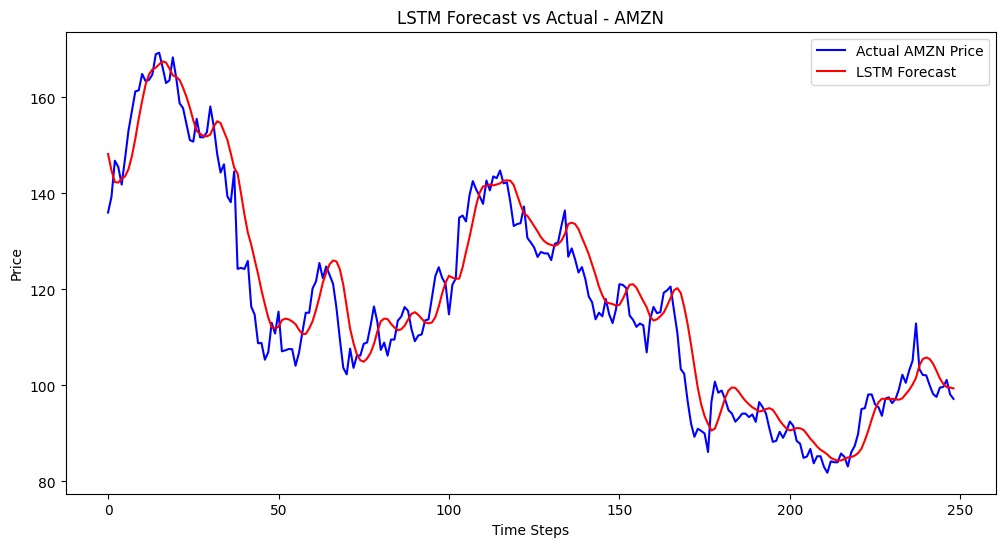

In [ ]:
# Plot LSTM Forecast vs Actual for AMZN
plt.figure(figsize=(12, 6))
plt.plot(y_test_inv_amzn, label='Actual AMZN Price', color='blue')
plt.plot(y_pred_inv_amzn, label='LSTM Forecast', color='red')
plt.title("LSTM Forecast vs Actual - AMZN")
plt.xlabel("Time Steps")
plt.ylabel("Price")
plt.legend()
plt.show()


In [ ]:
# Evaluate LSTM Forecast for AMZN
rmse_lstm_amzn = np.sqrt(mean_squared_error(y_test_inv_amzn, y_pred_inv_amzn))
mae_lstm_amzn = mean_absolute_error(y_test_inv_amzn, y_pred_inv_amzn)
print(f"AMZN LSTM RMSE: {rmse_lstm_amzn:.2f}")
print(f"AMZN LSTM MAE: {mae_lstm_amzn:.2f}")

AMZN LSTM RMSE: 6.06
AMZN LSTM MAE: 4.71


# **24-Month Future Forecast for AMZN using LSTM**

In [ ]:
# Recursive forecasting using the last window
last_window_amzn = scaled_amzn[-time_step:]
last_window_amzn = last_window_amzn.reshape((1, time_step, 1))
forecast_future_steps_amzn = 24 * 21  # 504 business days forecast
forecast_future_lstm_amzn = []
for _ in range(forecast_future_steps_amzn):
    pred = model_lstm_amzn.predict(last_window_amzn)
    forecast_future_lstm_amzn.append(pred[0, 0])
    # Append prediction and remove the first value to shift the window
    last_window_amzn = np.append(last_window_amzn[:, 1:, :], [[pred[0]]], axis=1)
forecast_future_lstm_amzn = np.array(forecast_future_lstm_amzn).reshape(-1, 1)
forecast_future_lstm_amzn_inv = scaler_amzn.inverse_transform(forecast_future_lstm_amzn)

future_dates_amzn_lstm = pd.date_range(start=ts_amzn.index[-1] + pd.Timedelta(days=1),
                                       periods=forecast_future_steps_amzn, freq='B')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━

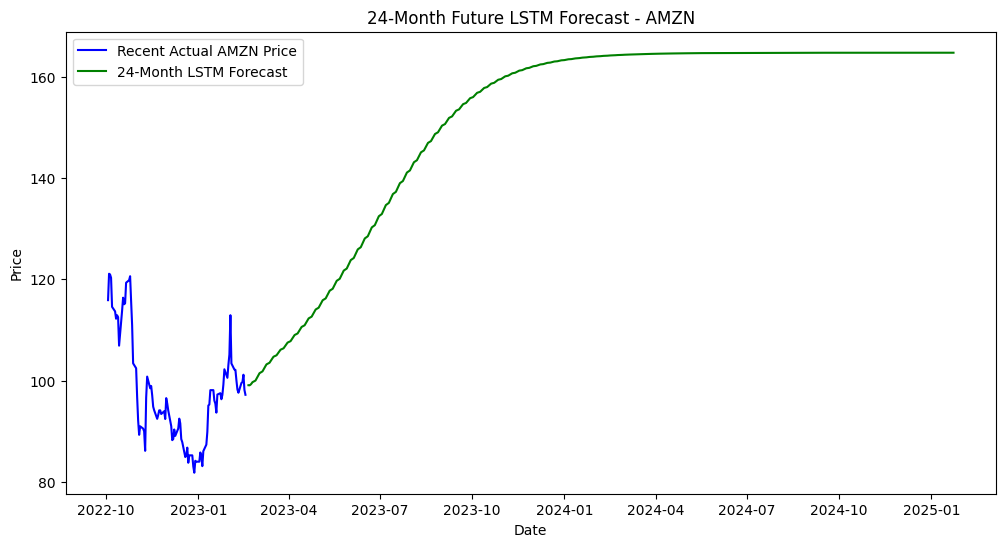

In [ ]:
# viual of 24 months future forecast
plt.figure(figsize=(12, 6))
plt.plot(ts_amzn.tail(100), label='Recent Actual AMZN Price', color='blue')
plt.plot(future_dates_amzn_lstm, forecast_future_lstm_amzn_inv, label='24-Month LSTM Forecast', color='green')
plt.title("24-Month Future LSTM Forecast - AMZN")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

# **Part 2: jj Dataset Analysis and Training**

In [ ]:
# 1. Load and Preprocess jj Dataset
data_jj = pd.read_csv('jj.csv')  # Load jj dataset
data_jj['date'] = pd.to_datetime(data_jj['date'])
data_jj.set_index('date', inplace=True)
data_jj = data_jj.asfreq('D')  # Adjust frequency to daily, if necessary


In [ ]:
# Check for missing values in jj dataset
print("\nMissing values in jj dataset:")
print(data_jj.isna().sum())


Missing values in jj dataset:
data    7496
dtype: int64


In [ ]:
# Handle missing values (if any) by forward filling
data_jj.fillna(method='ffill', inplace=True)
ts_jj = data_jj['data']  # Assuming 'Value' is the target variable


In [ ]:
print(data_jj.isna().sum())

data    0
dtype: int64


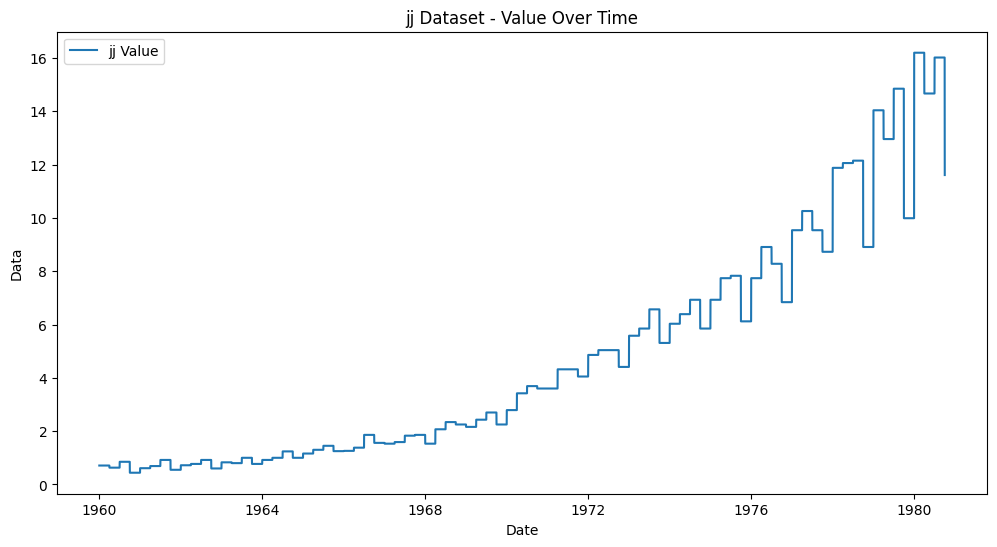

In [ ]:
# 2. Plot the jj Time Series
plt.figure(figsize=(12, 6))
plt.plot(ts_jj, label='jj Value')
plt.title("jj Dataset - Value Over Time")
plt.xlabel("Date")
plt.ylabel("Data")
plt.legend()
plt.show()


# **ARIMA Modeling for jj Dataset**

In [ ]:
# 3. Stationarity Test for jj Data
adf_test(ts_jj, title="jj Value - ADF Test")


--- jj Value - ADF Test ---
ADF Statistic: -1.2407
p-value: 0.6559
=> The series is likely non-stationary. Consider differencing.



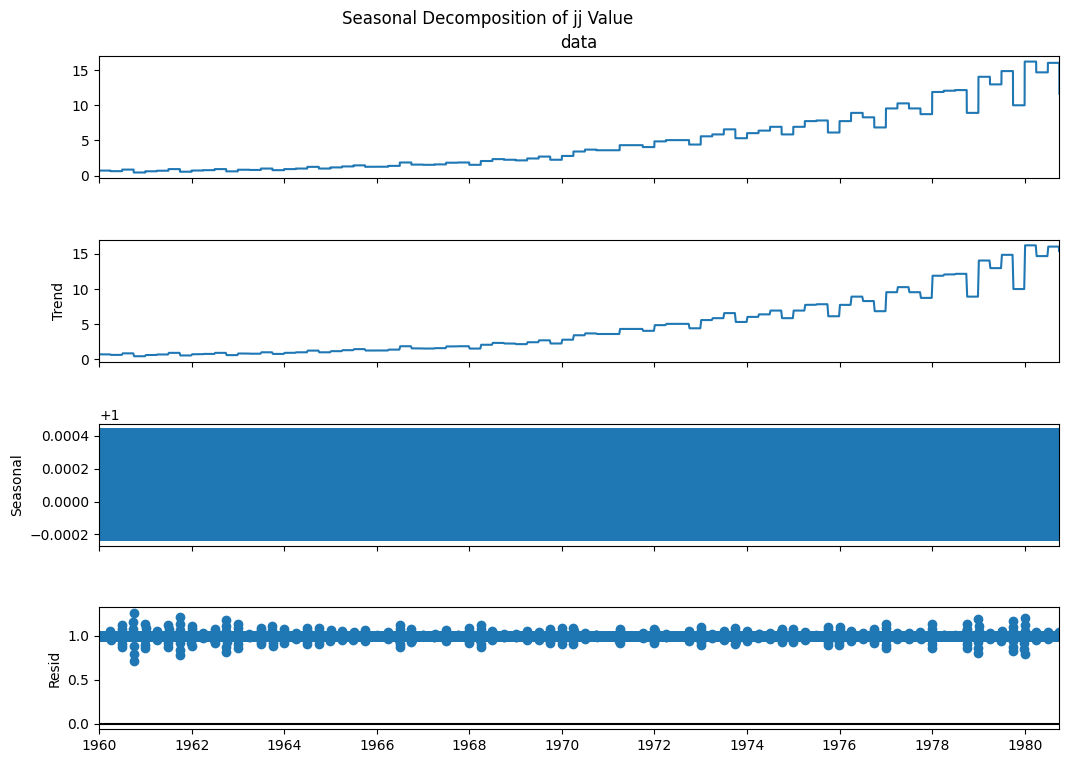

In [ ]:
# 4. Seasonal Decomposition for jj Data (exploratory)
try:
    decomposition_jj = seasonal_decompose(ts_jj, model='multiplicative')
    fig = decomposition_jj.plot()
    fig.set_size_inches(12, 8)
    plt.suptitle("Seasonal Decomposition of jj Value")
    plt.show()
except Exception as e:
    print("Seasonal Decomposition Error:", e)

In [ ]:
# 5. Differencing the Series (if the series is non-stationary)
diff_ts_jj = ts_jj.diff().dropna()


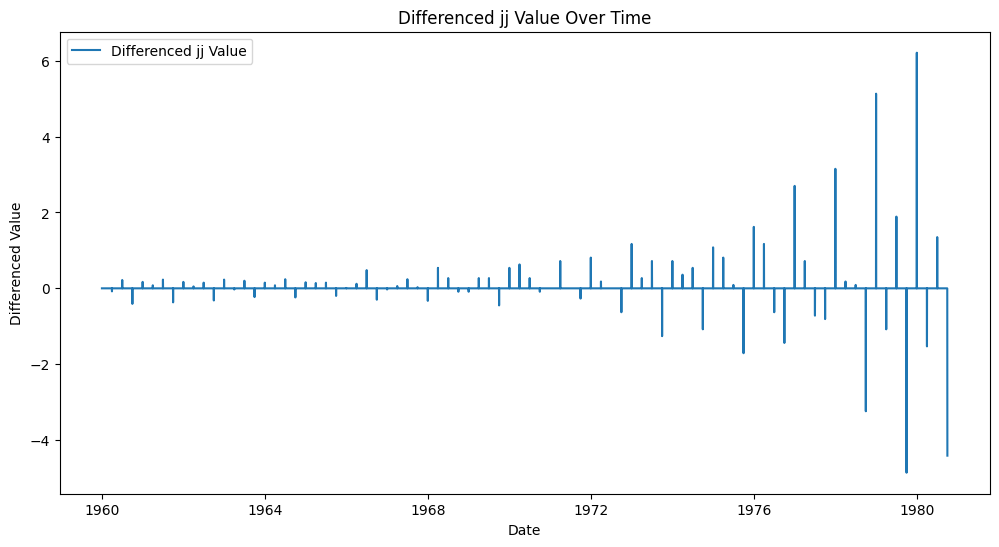

In [ ]:
# Plot the differenced series
plt.figure(figsize=(12, 6))
plt.plot(diff_ts_jj, label='Differenced jj Value')
plt.title("Differenced jj Value Over Time")
plt.xlabel("Date")
plt.ylabel("Differenced Value")
plt.legend()
plt.show()


In [ ]:
# Run ADF test on differenced series to check stationarity
adf_test(diff_ts_jj, title="Differenced jj Value - ADF Test")


--- Differenced jj Value - ADF Test ---
ADF Statistic: -81.8500
p-value: 0.0000
=> The series appears stationary.



In [ ]:
# 6. Split Data for ARIMA Modeling on jj dataset (80% train, 20% test)
train_size_jj = int(len(diff_ts_jj) * 0.8)
train_jj = diff_ts_jj.iloc[:train_size_jj]
test_jj = diff_ts_jj.iloc[train_size_jj:]
print("jj ARIMA Train samples:", len(train_jj))
print("jj ARIMA Test samples:", len(test_jj))

jj ARIMA Train samples: 6063
jj ARIMA Test samples: 1516


In [ ]:
# 7. ARIMA Model on jj Data
arima_model_jj = ARIMA(train_jj, order=(1, 0, 1))   #use ARIMA(1,1,1)=(p,d,q) when manual differencing is not applied
                                                       #to the data but in this case differencing is already
                                                        # applied so value of d=0, so use (1,0,1)
arima_model_fit_jj = arima_model_jj.fit()
print(arima_model_fit_jj.summary())


                               SARIMAX Results                                
Dep. Variable:                   data   No. Observations:                 6063
Model:                 ARIMA(1, 0, 1)   Log Likelihood                8800.445
Date:                Fri, 11 Apr 2025   AIC                         -17592.890
Time:                        03:48:20   BIC                         -17566.050
Sample:                    01-02-1960   HQIC                        -17583.574
                         - 08-07-1976                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0012      0.001      1.207      0.228      -0.001       0.003
ar.L1      -7.514e-07      0.292  -2.57e-06      1.000      -0.572       0.572
ma.L1       -7.67e-07      0.292  -2.63e-06      1.0

In [ ]:
# 8. ARIMA Forecast for jj Data
forecast_steps_jj = len(test_jj)
forecast_jj = arima_model_fit_jj.forecast(steps=forecast_steps_jj)
forecast_jj.index = test_jj.index


In [ ]:
# 9. Invert the ARIMA forecast to original scale for jj
last_value_jj = ts_jj.iloc[train_size_jj]  # Last observed original value from training period
forecast_jj_inv = forecast_jj.cumsum() + last_value_jj
test_actual_jj = ts_jj.iloc[train_size_jj+1:train_size_jj+1+len(forecast_jj_inv)]


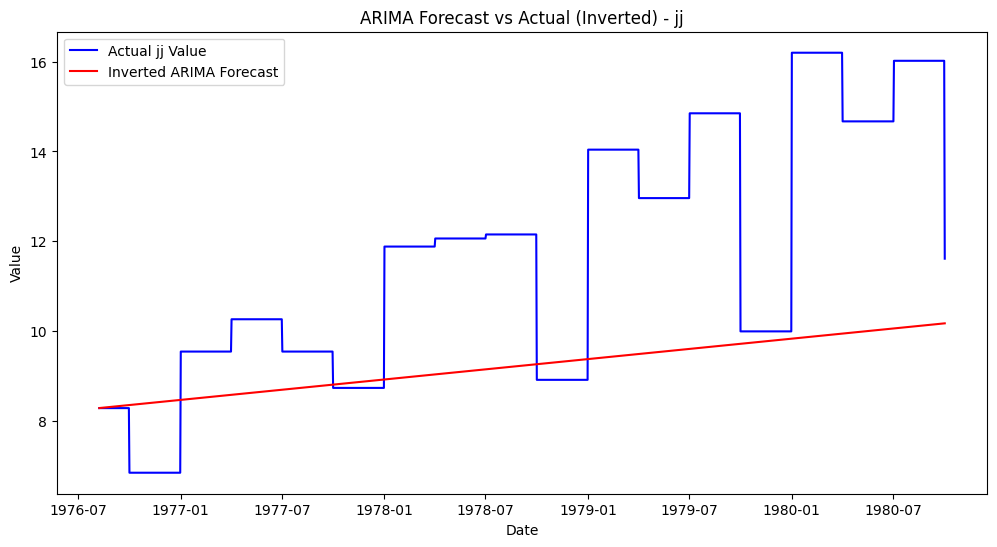

In [ ]:
# Plot ARIMA Forecast vs. Actual for jj
plt.figure(figsize=(12, 6))
plt.plot(test_actual_jj, label='Actual jj Value', color='blue')
plt.plot(forecast_jj_inv, label='Inverted ARIMA Forecast', color='red')
plt.title("ARIMA Forecast vs Actual (Inverted) - jj")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.show()


In [ ]:
rmse_arima_jj = np.sqrt(mean_squared_error(test_actual_jj, forecast_jj_inv))
mae_arima_jj = mean_absolute_error(test_actual_jj, forecast_jj_inv)
print(f"jj ARIMA RMSE (inverted): {rmse_arima_jj:.2f}")
print(f"jj ARIMA MAE (inverted): {mae_arima_jj:.2f}")

jj ARIMA RMSE (inverted): 3.38
jj ARIMA MAE (inverted): 2.69


# **24-Month Future Forecast for jj using ARIMA**

In [ ]:
# For the jj dataset (daily frequency), assume 30 days per month: 24 * 30 = 720 steps (adjust as necessary)
forecast_future_steps_jj = 24 * 30
forecast_future_jj = arima_model_fit_jj.forecast(steps=forecast_future_steps_jj)
future_dates_jj = pd.date_range(start=ts_jj.index[-1] + pd.Timedelta(days=1), periods=forecast_future_steps_jj, freq='D')
forecast_future_jj.index = future_dates_jj
last_value_jj_full = ts_jj.iloc[-1]
forecast_future_jj_inv = forecast_future_jj.cumsum() + last_value_jj_full


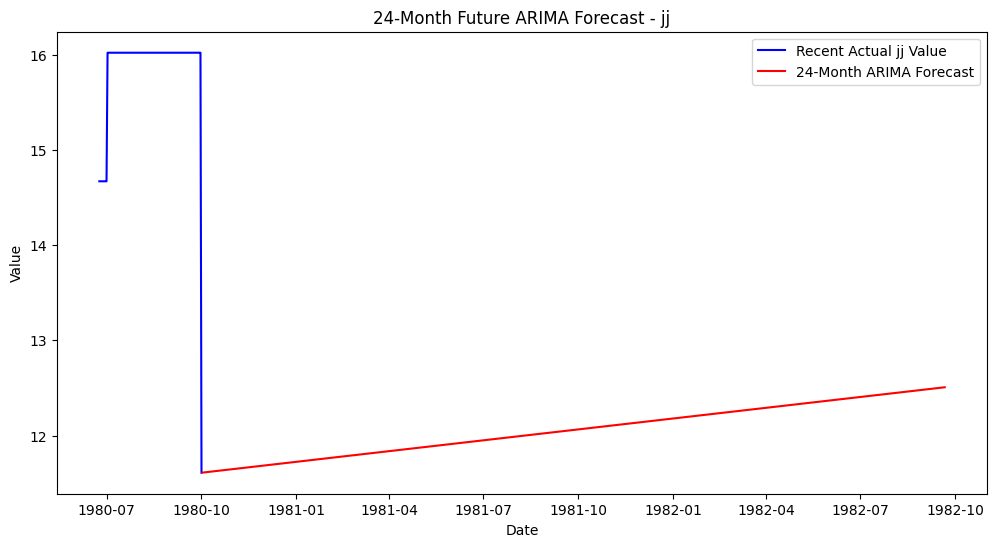

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(ts_jj.tail(100), label='Recent Actual jj Value', color='blue')
plt.plot(future_dates_jj, forecast_future_jj_inv, label='24-Month ARIMA Forecast', color='red')
plt.title("24-Month Future ARIMA Forecast - jj")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.show()


# **LSTM Modeling for jj Dataset**

In [ ]:
# Scale the data for jj
values_jj = ts_jj.values.reshape(-1, 1)
scaler_jj = MinMaxScaler(feature_range=(0, 1))
scaled_jj = scaler_jj.fit_transform(values_jj)

In [ ]:
# Create sequences for LSTM for jj
X_jj, y_jj = create_dataset(scaled_jj, time_step)


In [ ]:
# Split into training and test sets for LSTM
train_size_lstm_jj = int(len(X_jj) * 0.8)
X_train_jj, X_test_jj = X_jj[:train_size_lstm_jj], X_jj[train_size_lstm_jj:]
y_train_jj, y_test_jj = y_jj[:train_size_lstm_jj], y_jj[train_size_lstm_jj:]
print("jj LSTM Train samples:", X_train_jj.shape[0])
print("jj LSTM Test samples:", X_test_jj.shape[0])


jj LSTM Train samples: 6016
jj LSTM Test samples: 1504


In [ ]:
# Reshape for LSTM input: [samples, time steps, features]
X_train_jj = X_train_jj.reshape((X_train_jj.shape[0], X_train_jj.shape[1], 1))
X_test_jj = X_test_jj.reshape((X_test_jj.shape[0], X_test_jj.shape[1], 1))


In [ ]:
# Build the LSTM Model for jj Data
model_lstm_jj = Sequential()
model_lstm_jj.add(LSTM(50, return_sequences=True, input_shape=(time_step, 1)))
model_lstm_jj.add(LSTM(50))
model_lstm_jj.add(Dense(1))
model_lstm_jj.compile(optimizer='adam', loss='mean_squared_error')


In [ ]:
# Train the LSTM Model for jj Data
es_jj = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history_jj = model_lstm_jj.fit(X_train_jj, y_train_jj,
                               validation_split=0.2,
                               epochs=50,
                               batch_size=32,
                               callbacks=[es_jj],
                               verbose=1)

Epoch 1/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 13s 63ms/step - loss: 0.0022 - val_loss: 3.8276e-04
Epoch 2/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - loss: 3.0310e-05 - val_loss: 2.5073e-04
Epoch 3/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - loss: 2.7077e-05 - val_loss: 2.2824e-04
Epoch 4/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - loss: 3.0569e-05 - val_loss: 2.2818e-04
Epoch 5/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - loss: 3.2911e-05 - val_loss: 2.5518e-04
Epoch 6/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - loss: 2.7615e-05 - val_loss: 1.9829e-04
Epoch 7/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step - loss: 2.5231e-05 - val_loss: 1.7041e-04
Epoch 8/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - loss: 2.7796e-05 - val_loss: 1.7896e-04
Epoch 9/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 60ms/step - loss: 1.9192e-05 - val_loss: 1.7622e-04
Epoch 10/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - loss: 2.5838e-05 - val_loss: 1.9860e-04
Epoch 11/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 10s 61

In [ ]:
# Forecast with LSTM for jj Data
y_pred_jj = model_lstm_jj.predict(X_test_jj)
y_pred_inv_jj = scaler_jj.inverse_transform(y_pred_jj)
y_test_inv_jj = scaler_jj.inverse_transform(y_test_jj.reshape(-1, 1))

47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


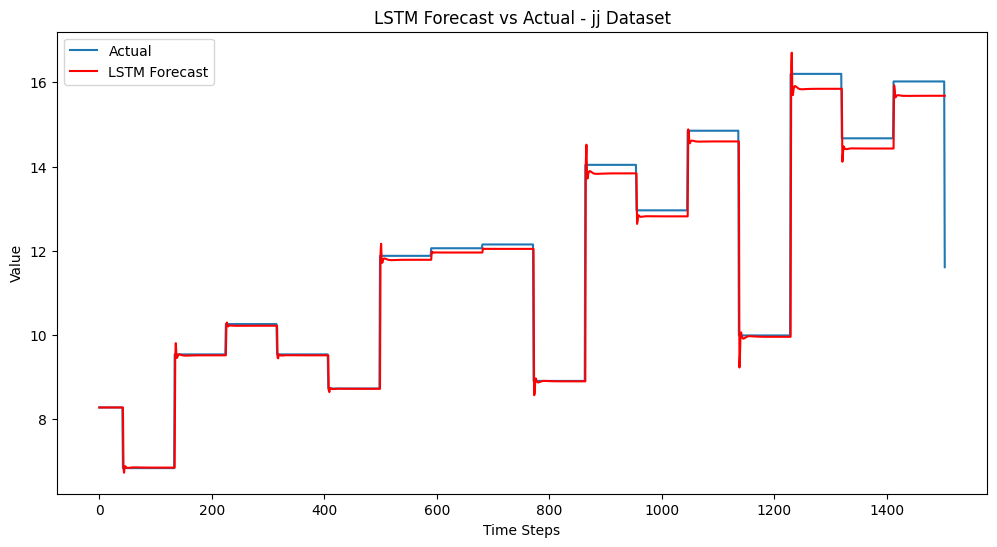

In [ ]:
# Plot LSTM Forecast vs Actual for jj
plt.figure(figsize=(12, 6))
plt.plot(y_test_inv_jj, label='Actual')
plt.plot(y_pred_inv_jj, label='LSTM Forecast', color='red')
plt.title("LSTM Forecast vs Actual - jj Dataset")
plt.xlabel("Time Steps")
plt.ylabel("Value")
plt.legend()
plt.show()

In [ ]:
# Evaluate LSTM Forecast for jj
rmse_lstm_jj = np.sqrt(mean_squared_error(y_test_inv_jj, y_pred_inv_jj))
mae_lstm_jj = mean_absolute_error(y_test_inv_jj, y_pred_inv_jj)
print(f"jj LSTM RMSE: {rmse_lstm_jj:.2f}")
print(f"jj LSTM MAE: {mae_lstm_jj:.2f}")

jj LSTM RMSE: 0.35
jj LSTM MAE: 0.15


# **24-Month Future Forecast for jj using LSTM**

In [ ]:
last_window_jj = scaled_jj[-time_step:]
last_window_jj = last_window_jj.reshape((1, time_step, 1))
forecast_future_steps_jj_lstm = 24 * 30  # e.g., 720 days forecast for daily data
forecast_future_lstm_jj = []
for _ in range(forecast_future_steps_jj_lstm):
    pred = model_lstm_jj.predict(last_window_jj)
    forecast_future_lstm_jj.append(pred[0, 0])
    last_window_jj = np.append(last_window_jj[:, 1:, :], [[pred[0]]], axis=1)
forecast_future_lstm_jj = np.array(forecast_future_lstm_jj).reshape(-1, 1)
forecast_future_lstm_jj_inv = scaler_jj.inverse_transform(forecast_future_lstm_jj)

future_dates_jj_lstm = pd.date_range(start=ts_jj.index[-1] + pd.Timedelta(days=1),
                                     periods=forecast_future_steps_jj_lstm, freq='D')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━

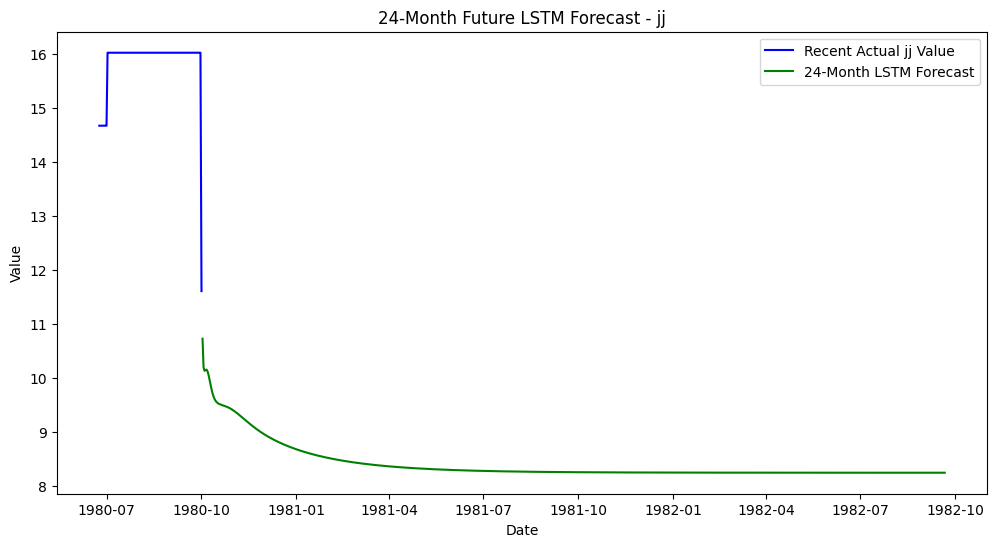

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(ts_jj.tail(100), label='Recent Actual jj Value', color='blue')
plt.plot(future_dates_jj_lstm, forecast_future_lstm_jj_inv, label='24-Month LSTM Forecast', color='green')
plt.title("24-Month Future LSTM Forecast - jj")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.show()


# **Comparison of Models with both the datasets**

In [ ]:
comparison_results = pd.DataFrame({
    'Dataset': ['AMZN', 'AMZN', 'jj', 'jj'],
    'Model': ['ARIMA', 'LSTM', 'ARIMA', 'LSTM'],
    'RMSE': [rmse_arima_amzn, rmse_lstm_amzn, rmse_arima_jj, rmse_lstm_jj],
    'MAE': [mae_arima_amzn, mae_lstm_amzn, mae_arima_jj, mae_lstm_jj]
})

print(comparison_results)


  Dataset  Model       RMSE        MAE
0    AMZN  ARIMA  54.410055  47.797833
1    AMZN   LSTM   6.056306   4.710926
2      jj  ARIMA   3.375728   2.690548
3      jj   LSTM   0.351524   0.146346


**Visual comparision of AMZN dataset with ARIMA forecast and LSTM forecast**

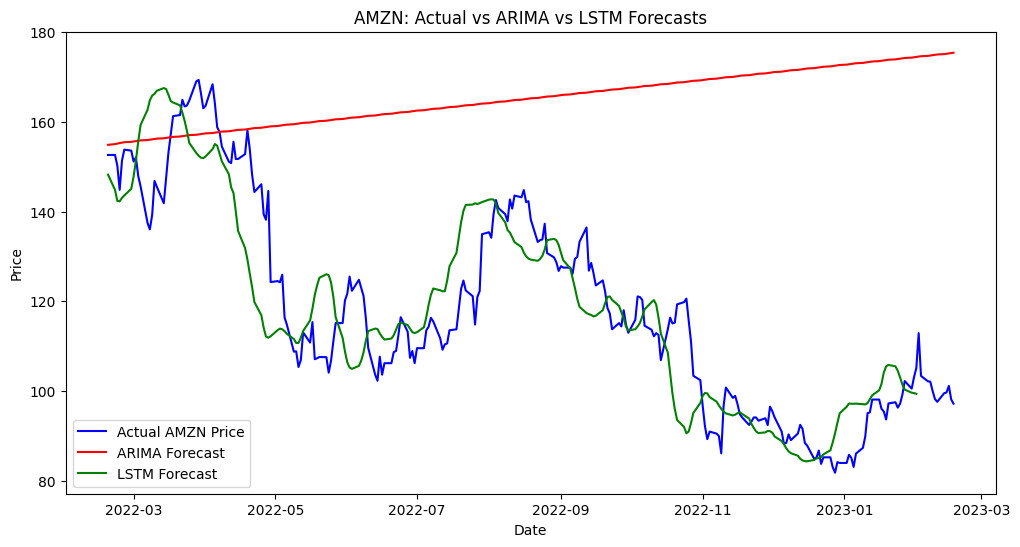

In [ ]:
# AMZN Comparison Plot
plt.figure(figsize=(12, 6))
plt.plot(test_actual_amzn.index, test_actual_amzn, label='Actual AMZN Price', color='blue')
plt.plot(test_actual_amzn.index, forecast_amzn_inv, label='ARIMA Forecast', color='red')
# Align indices for LSTM predictions for AMZN
lstm_index_amzn = test_actual_amzn.index[:len(y_pred_inv_amzn)]
plt.plot(lstm_index_amzn, y_pred_inv_amzn, label='LSTM Forecast', color='green')
plt.title("AMZN: Actual vs ARIMA vs LSTM Forecasts")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

**Visual comparision of jj dataset with ARIMA forecast and LSTM forecast**

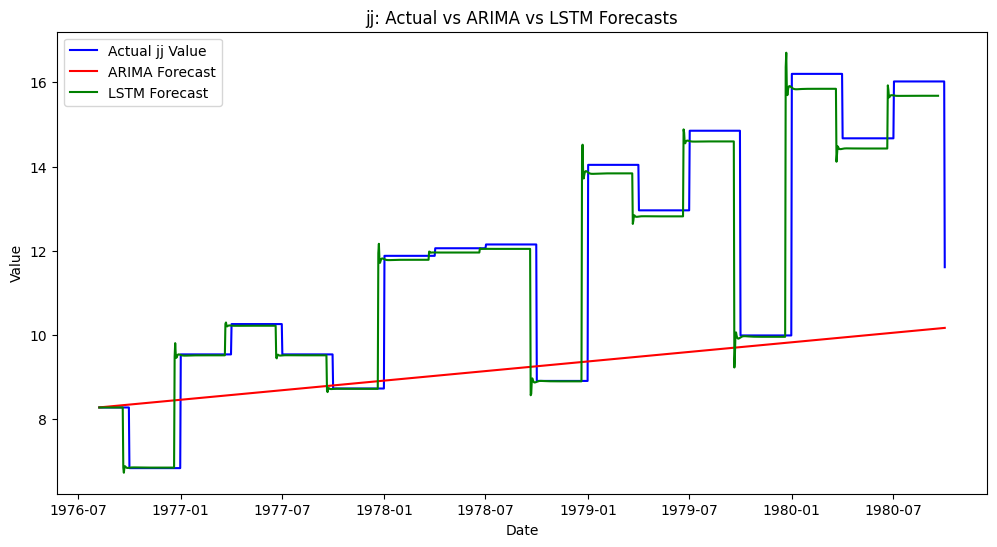

In [ ]:
# jj Comparison Plot
plt.figure(figsize=(12, 6))
plt.plot(test_actual_jj.index, test_actual_jj, label='Actual jj Value', color='blue')
plt.plot(test_actual_jj.index, forecast_jj_inv, label='ARIMA Forecast', color='red')
lstm_index_jj = test_actual_jj.index[:len(y_pred_inv_jj)]
plt.plot(lstm_index_jj, y_pred_inv_jj, label='LSTM Forecast', color='green')
plt.title("jj: Actual vs ARIMA vs LSTM Forecasts")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.show()